# 02 · Exploratory Data Analysis

Report ka **Exploratory Data Analysis** section: descriptive statistics, visualisations and correlation analysis.

Figures `reports/figures/` mein aur tables `reports/tables/` mein save hote hain.

## 1. Imports, paths, style

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
%matplotlib inline
from pathlib import Path

# Notebook ka __file__ nahi hota, isliye current folder se project root dhoondhte hain.
# Notebook "notebooks/" ke andar se chale ya root se, dono mein ROOT = SML_AAT hi milega.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA = ROOT / "data" / "processed" / "bengaluru_clean.csv"
FIG = ROOT / "reports" / "figures"
TAB = ROOT / "reports" / "tables"
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
POLL = ["PM2.5", "PM10", "NO", "NO2", "NOx", "NH3", "CO", "SO2", "O3", "Benzene", "Toluene"]
ORDER = ["Winter", "Summer", "Monsoon", "Post-monsoon"]

df = pd.read_csv(DATA, parse_dates=["Date"])
df.shape

(1699, 20)

## 2. Descriptive statistics

Skew aur kurtosis bhi add kiye hain. Agar PM2.5 bahut right-skewed hai, to regression mein log transform consider karenge.

In [2]:
desc = df[POLL].describe().T
desc["skew"] = df[POLL].skew()
desc["kurtosis"] = df[POLL].kurt()
desc.round(2).to_csv(TAB / "descriptive_stats.csv")
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
PM2.5,1649.0,35.23,18.10,1.72,21.84,31.67,44.26,204.25,1.84,8.82
PM10,1677.0,83.38,38.08,8.22,56.42,77.55,104.35,351.51,1.22,3.37
NO,1699.0,10.01,7.38,0.87,5.60,8.19,12.34,95.19,3.64,25.28
NO2,1699.0,29.84,13.08,3.00,21.07,28.60,36.10,142.35,1.60,6.82
NOx,1699.0,20.73,15.87,0.00,7.44,21.33,30.42,147.06,0.93,3.52
NH3,1548.0,22.61,13.21,0.15,14.39,20.02,26.40,120.07,2.54,10.00
CO,1699.0,0.98,0.79,0.00,0.69,0.87,1.04,9.04,6.00,45.28
SO2,1699.0,5.32,2.20,0.87,3.95,5.13,6.41,24.02,2.48,15.26
O3,1592.0,34.16,17.10,1.83,20.32,32.30,46.60,109.97,0.54,-0.10
Benzene,1585.0,1.14,1.48,0.00,0.43,0.77,1.32,27.62,6.72,82.69


## 3. Distributions

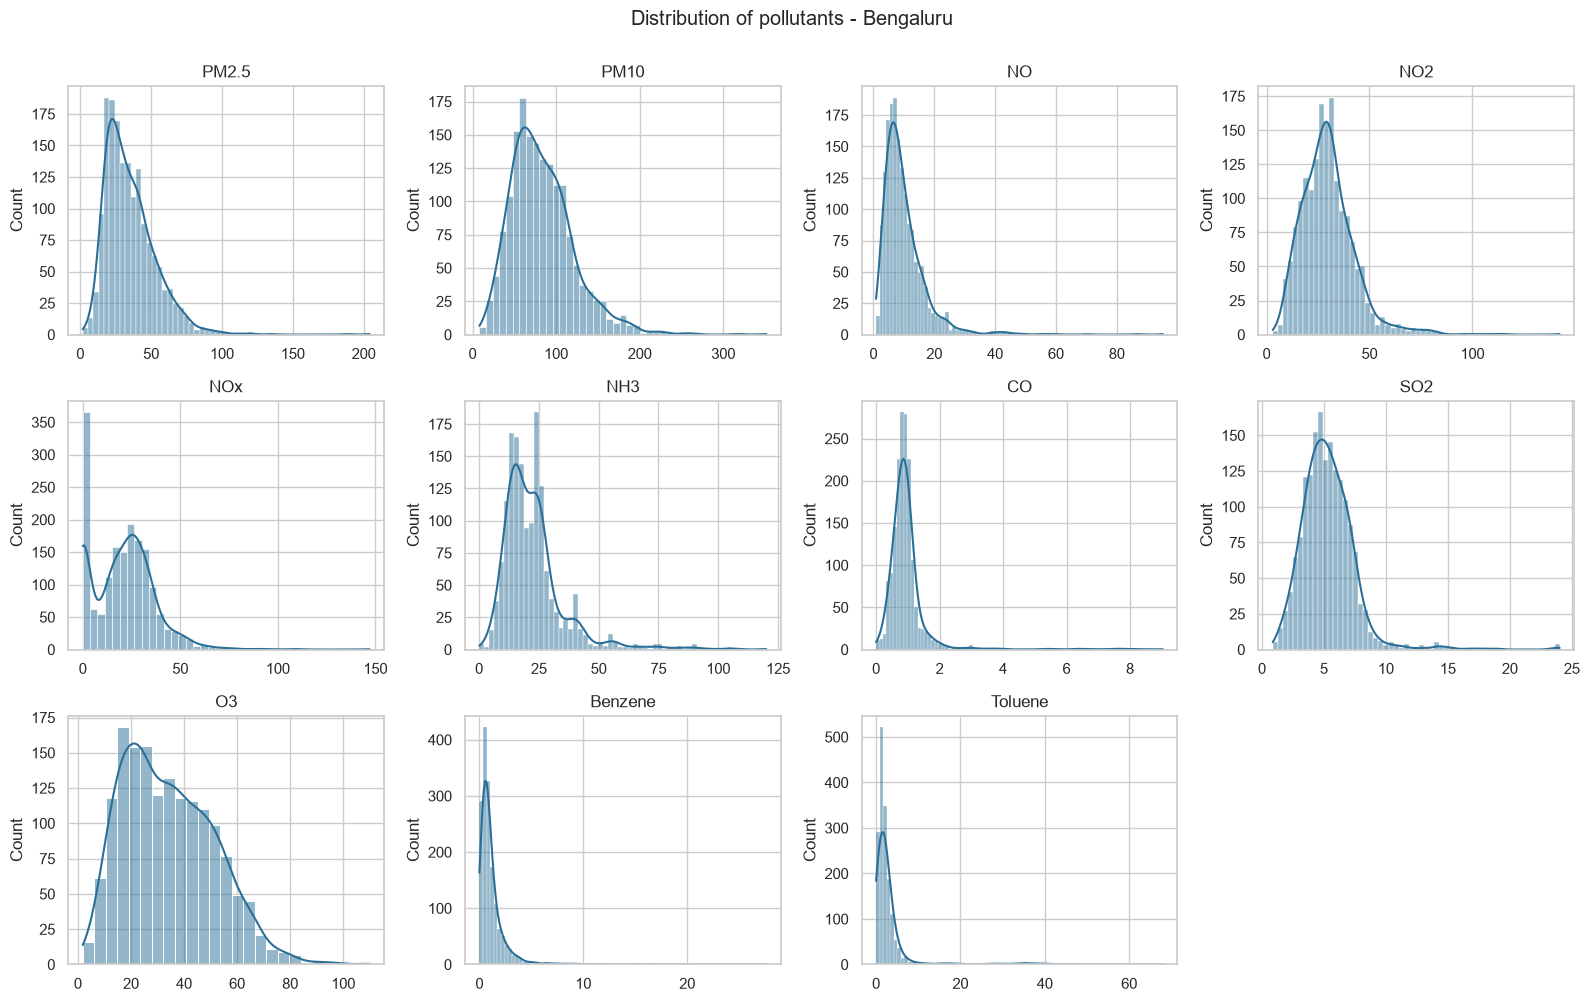

In [ ]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, c in zip(axes.ravel(), POLL):
    sns.histplot(df[c], kde=True, ax=ax, color="#2a6f97")
    ax.set_title(c); ax.set_xlabel("")
axes.ravel()[-1].axis("off") ##this is to remove the last empty subplot
fig.suptitle("Distribution of pollutants - Bengaluru", y=1.0)
fig.tight_layout()
fig.savefig(FIG / "01_histograms.png", dpi=150)
plt.show()

**Observation:** zyada tar pollutants right-skewed hain. PM2.5 mein 100+ ke spike days ki lambi tail hai.

## 4. PM2.5 over time

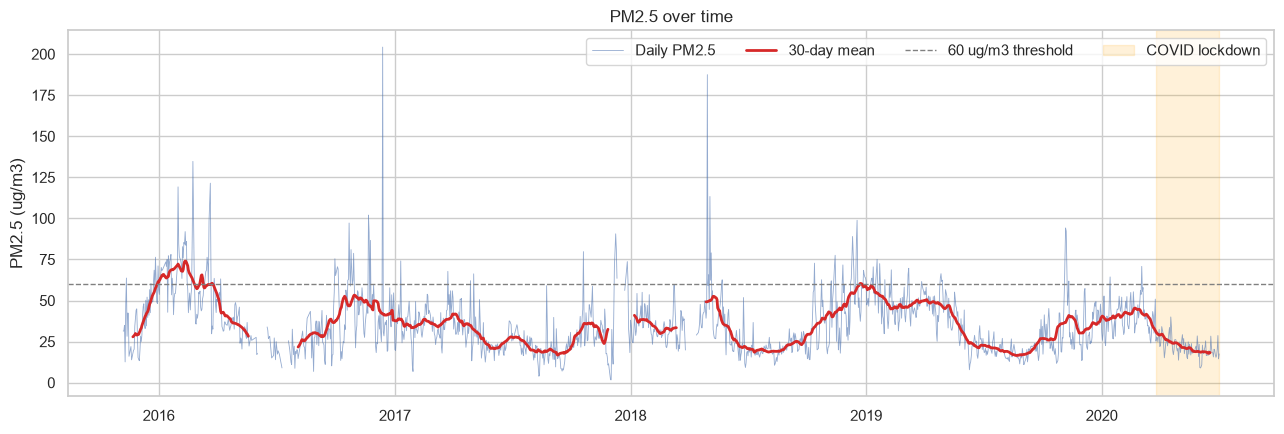

In [4]:
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(df["Date"], df["PM2.5"], lw=0.6, alpha=0.6, label="Daily PM2.5")
ax.plot(df["Date"], df["PM2.5"].rolling(30, center=True).mean(), lw=2, color="#d62828", label="30-day mean")
ax.axhline(60, ls="--", color="grey", lw=1, label="60 ug/m3 threshold")
ax.axvspan(pd.Timestamp("2020-03-25"), df["Date"].max(), color="orange", alpha=0.15, label="COVID lockdown")
ax.set_ylabel("PM2.5 (ug/m3)"); ax.set_title("PM2.5 over time")
ax.legend(ncol=4, loc="upper right")
fig.tight_layout()
fig.savefig(FIG / "02_pm25_timeseries.png", dpi=150)
plt.show()

**Observation:** har saal winter peak aur monsoon dip dikhta hai. Lockdown mein level saaf neeche gaya.

## 5. Seasonality

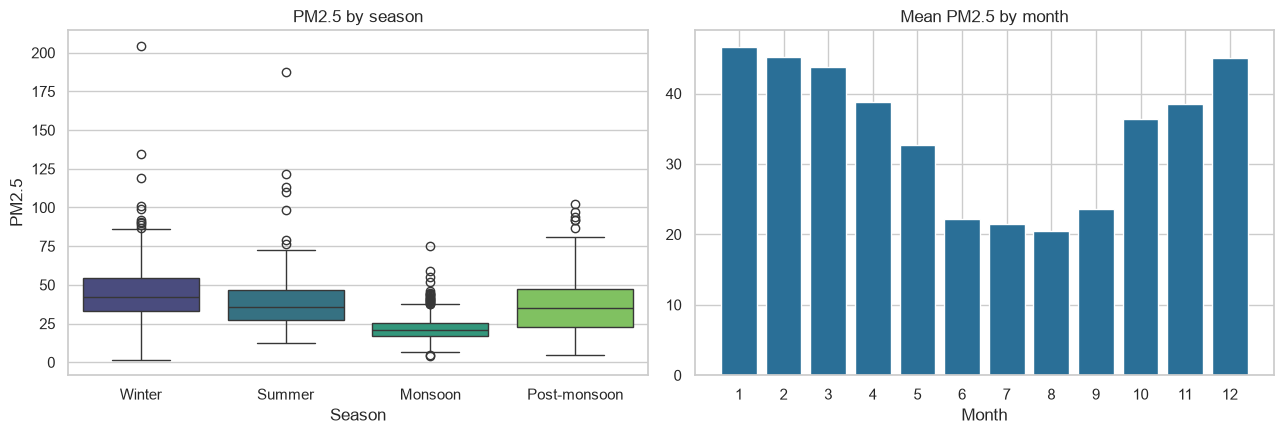

,mean,median,std,max
Season,,,,
Winter,45.6,42.3,19.1,204.2
Summer,38.3,35.7,16.4,187.5
Monsoon,21.9,20.7,7.9,75.4
Post-monsoon,37.6,34.9,18.1,102.0


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=df, x="Season", y="PM2.5", order=ORDER, hue="Season", hue_order=ORDER,
            palette="viridis", legend=False, ax=axes[0])
axes[0].set_title("PM2.5 by season")
monthly = df.groupby("Month")["PM2.5"].mean()
axes[1].bar(monthly.index, monthly.values, color="#2a6f97")
axes[1].set_xticks(range(1, 13)); axes[1].set_title("Mean PM2.5 by month"); axes[1].set_xlabel("Month")
fig.tight_layout()
fig.savefig(FIG / "03_seasonality.png", dpi=150)
plt.show()

season_tbl = df.groupby("Season")["PM2.5"].agg(["mean", "median", "std", "max"]).reindex(ORDER).round(1)
season_tbl.to_csv(TAB / "pm25_by_season.csv")
season_tbl

## 6. Correlation analysis

NO, NO2 aur NOx chemically linked hain, isliye regression mein multicollinearity (VIF) check karni padegi.

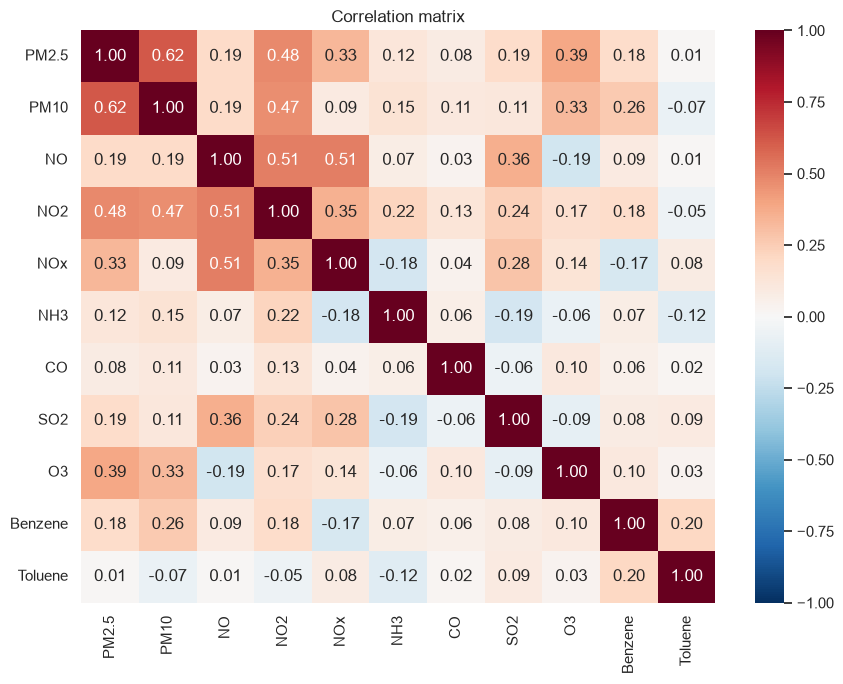

,corr_with_PM2.5
PM10,0.62
NO2,0.48
O3,0.39
NOx,0.33
NO,0.19
SO2,0.19
Benzene,0.18
NH3,0.12
CO,0.08
Toluene,0.01


In [6]:
corr = df[POLL].corr()
corr.round(2).to_csv(TAB / "correlation_matrix.csv")
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation matrix")
fig.tight_layout()
fig.savefig(FIG / "04_correlation_heatmap.png", dpi=150)
plt.show()

corr["PM2.5"].drop("PM2.5").sort_values(ascending=False).round(2).to_frame("corr_with_PM2.5")

## 7. PM2.5 vs key predictors

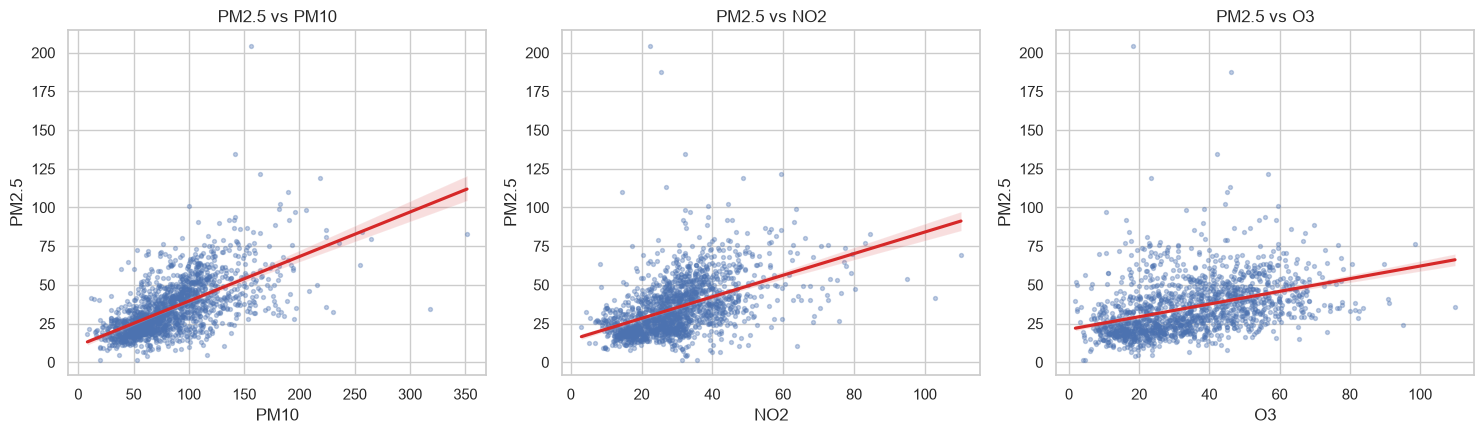

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, c in zip(axes, ["PM10", "NO2", "O3"]):
    sns.regplot(data=df, x=c, y="PM2.5", ax=ax, scatter_kws={"s": 8, "alpha": 0.35}, line_kws={"color": "#d62828"})##regplot is used to plot scatter plot with regression line
    ax.set_title(f"PM2.5 vs {c}")
fig.tight_layout()
fig.savefig(FIG / "05_scatter_pm25.png", dpi=150)
plt.show()

## 8. Year-wise trend and lockdown effect

In [8]:
year_tbl = df.groupby("Year")["PM2.5"].agg(["count", "mean", "median", "max"]).round(1)
year_tbl.to_csv(TAB / "pm25_by_year.csv")
lock = df.groupby("Lockdown")["PM2.5"].agg(["count", "mean"]).round(1)
lock.to_csv(TAB / "pm25_lockdown.csv")
display(year_tbl, lock)
print(f"Lockdown drop: {(1 - lock.loc[1, 'mean'] / lock.loc[0, 'mean']):.0%}")
print(f"Unhealthy days: {df['Unhealthy'].sum()} of {len(df)}")

,count,mean,median,max
Year,,,,
2015,55,38.4,39.7,76.4
2016,343,43.5,39.0,204.2
2017,354,30.1,27.9,90.6
2018,349,34.4,30.3,187.5
2019,365,35.1,33.9,94.2
2020,183,30.4,27.5,70.8


,count,mean
Lockdown,,
0,1550,36.1
1,99,21.7


Lockdown drop: 40%
Unhealthy days: 149 of 1699


## Key observations

1. **Right-skewed target:** PM2.5 skew ≈ 1.8, with a tail of spike days above 100 µg/m³. Non-normal residuals are expected, so a log transform will be tested.
2. **Strong seasonality:** winter mean ≈ 45.6 vs monsoon ≈ 21.9 µg/m³ (about 2×).
3. **Shared sources:** PM2.5 correlates most with PM10 (0.62) and NO2 (0.48), pointing to road dust and traffic.
4. **Multicollinearity risk:** NO, NO2 and NOx are chemically related, so VIF will be checked.
5. **Persistence:** polluted days cluster together, so a low Durbin-Watson is expected.
6. **Natural experiment:** the COVID lockdown cut mean PM2.5 by ~40% (36.1 → 21.7).
7. **Year-to-year:** 2016 was the worst year (mean 43.5); 2017-2020 stayed around 30-35.